<a href="https://colab.research.google.com/github/camsmugereski/BU-OMDS-Capstone/blob/main/OMDS_ModC1_Week1_Smugereski_Cameron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 1 Jupyter Notebook – Linear Regression 1
## Systemic Banking Risk and Credit Risk Analysis

### Project Overview

This project examines systemic banking risk by analyzing how borrower characteristics, macroeconomic conditions, and banking system indicators relate to financial risk. The overall capstone uses borrower-level credit risk data, macroeconomic data from FRED, and banking system indicators from the FDIC.

For Week 1, I focus on the borrower-level Credit Risk dataset. My previous analysis found relationships among several borrower and loan characteristics, including a positive relationship between borrower income and loan amount. This notebook expands that analysis using multiple linear regression.

The primary question for this notebook is:

**How well can borrower and loan characteristics explain variation in loan amount, and do polynomial and interaction terms improve the model?**

The analysis includes:
- Continuous and categorical features
- Multiple linear regression
- Polynomial terms
- Interaction terms
- Multicollinearity
- Variance Inflation Factor (VIF)
- Train/test evaluation
- Comparison of model performance

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option('display.max_columns', None)

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving credit_risk_dataset 2.csv to credit_risk_dataset 2.csv


In [ ]:
df = pd.read_csv("credit_risk_dataset 2.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [ ]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
display(df.isnull().sum())

print("\nSummary Statistics:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB

Missing V

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0



Summary Statistics:


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


## Initial Data Exploration

Before building the regression models, I examined the structure of the dataset, missing values, and descriptive statistics.

The Credit Risk dataset contains both continuous and categorical variables. This makes it useful for examining how different types of borrower characteristics contribute to loan behavior.

For this analysis, `loan_amnt` will be the dependent variable because it is continuous and therefore appropriate for linear regression.

In [ ]:
target = 'loan_amnt'

continuous_features = [
    'person_age',
    'person_income',
    'person_emp_length',
    'loan_int_rate',
    'loan_percent_income',
    'cb_person_cred_hist_length'
]

categorical_features = [
    'person_home_ownership',
    'loan_intent',
    'loan_grade',
    'cb_person_default_on_file'
]

model_columns = continuous_features + categorical_features + [target]

data = df[model_columns].copy()

print("Rows before removing missing values:", len(data))

data = data.dropna()

print("Rows after removing missing values:", len(data))

data.head()

Rows before removing missing values: 32581
Rows after removing missing values: 28638


,person_age,person_income,person_emp_length,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file,loan_amnt
0,22,59000,123.0,16.02,0.59,3,RENT,PERSONAL,D,Y,35000
1,21,9600,5.0,11.14,0.10,2,OWN,EDUCATION,B,N,1000
2,25,9600,1.0,12.87,0.57,3,MORTGAGE,MEDICAL,C,N,5500
3,23,65500,4.0,15.23,0.53,2,RENT,MEDICAL,C,N,35000
4,24,54400,8.0,14.27,0.55,4,RENT,MEDICAL,C,Y,35000


## Continuous and Categorical Features

The regression model contains both continuous and categorical predictors.

Continuous predictors include borrower age, income, employment length, interest rate, loan-to-income percentage, and credit history length.

Categorical predictors include home ownership, loan intent, loan grade, and whether the borrower has previously defaulted.

Categorical variables cannot be entered directly into a standard linear regression model, so they will be converted into dummy variables using one-hot encoding.

In [ ]:
correlation_columns = continuous_features + [target]

correlations = data[correlation_columns].corr()

display(correlations.round(3))

,person_age,person_income,person_emp_length,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,loan_amnt
person_age,1.000,0.179,0.166,0.011,-0.041,0.860,0.054
person_income,0.179,1.000,0.137,-0.001,-0.252,0.117,0.266
person_emp_length,0.166,0.137,1.000,-0.056,-0.055,0.146,0.111
loan_int_rate,0.011,-0.001,-0.056,1.000,0.123,0.015,0.146
loan_percent_income,-0.041,-0.252,-0.055,0.123,1.000,-0.030,0.577
cb_person_cred_hist_length,0.860,0.117,0.146,0.015,-0.030,1.000,0.045
loan_amnt,0.054,0.266,0.111,0.146,0.577,0.045,1.000


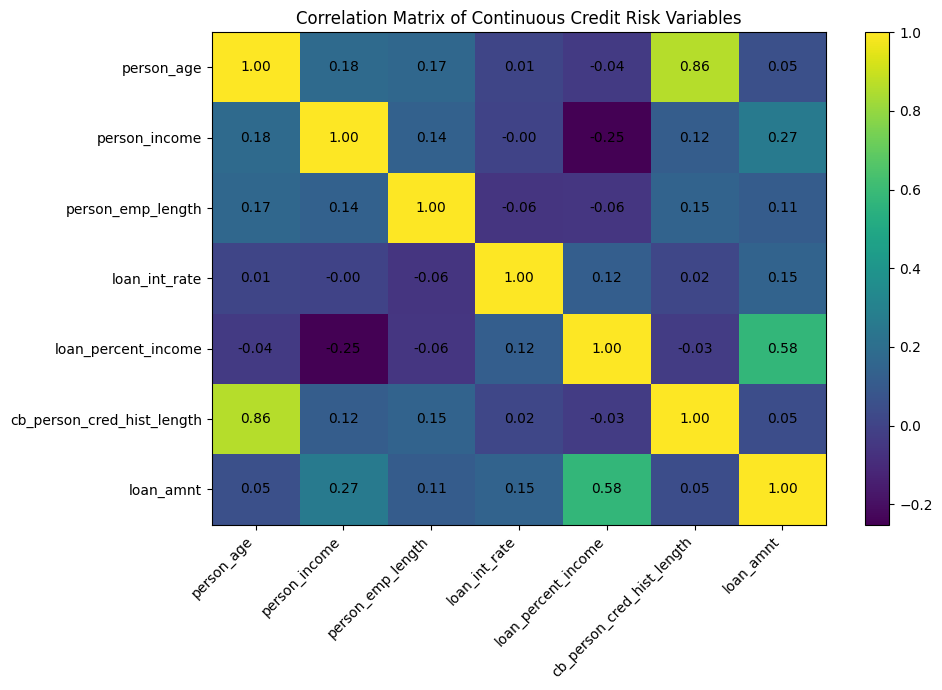

In [ ]:
fig, ax = plt.subplots(figsize=(10, 7))

im = ax.imshow(correlations, aspect='auto')

ax.set_xticks(range(len(correlations.columns)))
ax.set_xticklabels(correlations.columns, rotation=45, ha='right')

ax.set_yticks(range(len(correlations.columns)))
ax.set_yticklabels(correlations.columns)

for i in range(len(correlations.columns)):
    for j in range(len(correlations.columns)):
        ax.text(
            j,
            i,
            f"{correlations.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Correlation Matrix of Continuous Credit Risk Variables")
plt.colorbar(im)
plt.tight_layout()
plt.show()

## Exploratory Data Analysis and Multicollinearity

The correlation matrix provides an initial indication of relationships among the continuous predictors.

Strong correlations between independent variables are important because they may indicate multicollinearity. Multicollinearity occurs when predictors contain overlapping information, making individual regression coefficients more difficult to interpret.

Variance Inflation Factor (VIF) will be used next to examine multicollinearity more directly.

In [ ]:
vif_data = data[continuous_features].copy()

# Standardize before calculating VIF
scaler = StandardScaler()
vif_scaled = scaler.fit_transform(vif_data)

vif_df = pd.DataFrame()
vif_df["Feature"] = continuous_features
vif_df["VIF"] = [
    variance_inflation_factor(vif_scaled, i)
    for i in range(vif_scaled.shape[1])
]

vif_df = vif_df.sort_values("VIF", ascending=False)

display(vif_df)

,Feature,VIF
0,person_age,3.937336
5,cb_person_cred_hist_length,3.851113
1,person_income,1.119951
4,loan_percent_income,1.085451
2,person_emp_length,1.045121
3,loan_int_rate,1.020038


## Variance Inflation Factor

VIF measures how strongly the variance of a regression coefficient is increased because of relationships with other predictors.

As a general guideline:

- VIF near 1 indicates little multicollinearity.
- VIF above 5 may indicate potentially important multicollinearity.
- VIF above 10 is often considered evidence of serious multicollinearity.

I use VIF together with the correlation matrix rather than relying on either measure alone.

In [ ]:
X = data[continuous_features + categorical_features]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 22910
Testing observations: 5728


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('continuous', StandardScaler(), continuous_features),
        ('categorical', OneHotEncoder(drop='first', handle_unknown='ignore'),
         categorical_features)
    ]
)

baseline_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('regression', LinearRegression())
    ]
)

baseline_model.fit(X_train, y_train)

train_predictions = baseline_model.predict(X_train)
test_predictions = baseline_model.predict(X_test)

baseline_train_r2 = r2_score(y_train, train_predictions)
baseline_test_r2 = r2_score(y_test, test_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
baseline_mae = mean_absolute_error(y_test, test_predictions)

print("Baseline Multiple Linear Regression")
print("-----------------------------------")
print(f"Training R²: {baseline_train_r2:.4f}")
print(f"Testing R²:  {baseline_test_r2:.4f}")
print(f"Test RMSE:   {baseline_rmse:.2f}")
print(f"Test MAE:    {baseline_mae:.2f}")

Baseline Multiple Linear Regression
-----------------------------------
Training R²: 0.5376
Testing R²:  0.5929
Test RMSE:   4046.24
Test MAE:    2901.33


## Baseline Multiple Linear Regression

The baseline model expands on my previous simple regression analysis by considering several borrower characteristics simultaneously.

I evaluate the model using:

- **R²:** the proportion of variation in loan amount explained by the predictors.
- **RMSE:** the typical magnitude of prediction errors, with larger errors receiving more weight.
- **MAE:** the average absolute difference between predicted and actual loan amounts.

I also compare training and testing R². A substantially higher training R² than testing R² can indicate overfitting.

In [ ]:
poly_data = data.copy()

# Scale income before squaring it to keep values manageable
poly_data['income_scaled'] = (
    poly_data['person_income'] - poly_data['person_income'].mean()
) / poly_data['person_income'].std()

poly_data['income_squared'] = poly_data['income_scaled'] ** 2

poly_data[
    ['person_income', 'income_scaled', 'income_squared', 'loan_amnt']
].head()

,person_income,income_scaled,income_squared,loan_amnt
0,59000,-0.122672,0.015048,35000
1,9600,-0.914891,0.837026,1000
2,9600,-0.914891,0.837026,5500
3,65500,-0.018432,0.000340,35000
4,54400,-0.196441,0.038589,35000


## Polynomial Term

A standard linear regression assumes that the relationship between a predictor and the outcome is linear. However, financial relationships may not always follow a straight line.

My previous analysis found a positive relationship between income and loan amount, but the observations showed substantial variation around the regression line. Therefore, I test whether adding a squared income term captures nonlinear behavior.

Income is standardized before creating the squared term. Centering/scaling the variable also reduces unnecessary multicollinearity between the original income variable and its polynomial term.

In [ ]:
poly_continuous_features = [
    'person_age',
    'income_scaled',
    'income_squared',
    'person_emp_length',
    'loan_int_rate',
    'loan_percent_income',
    'cb_person_cred_hist_length'
]

X_poly = poly_data[poly_continuous_features + categorical_features]
y_poly = poly_data[target]

X_train_poly, X_test_poly, y_train_poly, y_test_poly = train_test_split(
    X_poly,
    y_poly,
    test_size=0.20,
    random_state=42
)

poly_preprocessor = ColumnTransformer(
    transformers=[
        ('continuous', StandardScaler(), poly_continuous_features),
        ('categorical', OneHotEncoder(drop='first', handle_unknown='ignore'),
         categorical_features)
    ]
)

poly_model = Pipeline(
    steps=[
        ('preprocessor', poly_preprocessor),
        ('regression', LinearRegression())
    ]
)

poly_model.fit(X_train_poly, y_train_poly)

poly_train_pred = poly_model.predict(X_train_poly)
poly_test_pred = poly_model.predict(X_test_poly)

poly_train_r2 = r2_score(y_train_poly, poly_train_pred)
poly_test_r2 = r2_score(y_test_poly, poly_test_pred)
poly_rmse = np.sqrt(mean_squared_error(y_test_poly, poly_test_pred))
poly_mae = mean_absolute_error(y_test_poly, poly_test_pred)

print("Polynomial Regression")
print("---------------------")
print(f"Training R²: {poly_train_r2:.4f}")
print(f"Testing R²:  {poly_test_r2:.4f}")
print(f"Test RMSE:   {poly_rmse:.2f}")
print(f"Test MAE:    {poly_mae:.2f}")

Polynomial Regression
---------------------
Training R²: 0.6545
Testing R²:  0.6819
Test RMSE:   3576.87
Test MAE:    2374.69


## Interaction Term

An interaction term tests whether the relationship between one predictor and the outcome depends on another predictor.

For this analysis, I examine the interaction between borrower income and loan percent income.

This is relevant because the meaning of a particular loan amount may depend on the borrower's income. A loan representing a small percentage of income may have a different relationship with loan amount than the same borrowing behavior for a lower-income borrower.

In [ ]:
interaction_data = poly_data.copy()

interaction_data['income_x_loan_percent'] = (
    interaction_data['income_scaled'] *
    interaction_data['loan_percent_income']
)

interaction_data[
    [
        'person_income',
        'loan_percent_income',
        'income_x_loan_percent',
        'loan_amnt'
    ]
].head()

,person_income,loan_percent_income,income_x_loan_percent,loan_amnt
0,59000,0.59,-0.072376,35000
1,9600,0.10,-0.091489,1000
2,9600,0.57,-0.521488,5500
3,65500,0.53,-0.009769,35000
4,54400,0.55,-0.108043,35000


In [ ]:
interaction_continuous_features = [
    'person_age',
    'income_scaled',
    'income_squared',
    'person_emp_length',
    'loan_int_rate',
    'loan_percent_income',
    'cb_person_cred_hist_length',
    'income_x_loan_percent'
]

X_interaction = interaction_data[
    interaction_continuous_features + categorical_features
]

y_interaction = interaction_data[target]

X_train_int, X_test_int, y_train_int, y_test_int = train_test_split(
    X_interaction,
    y_interaction,
    test_size=0.20,
    random_state=42
)

interaction_preprocessor = ColumnTransformer(
    transformers=[
        ('continuous', StandardScaler(), interaction_continuous_features),
        ('categorical', OneHotEncoder(drop='first', handle_unknown='ignore'),
         categorical_features)
    ]
)

interaction_model = Pipeline(
    steps=[
        ('preprocessor', interaction_preprocessor),
        ('regression', LinearRegression())
    ]
)

interaction_model.fit(X_train_int, y_train_int)

interaction_train_pred = interaction_model.predict(X_train_int)
interaction_test_pred = interaction_model.predict(X_test_int)

interaction_train_r2 = r2_score(y_train_int, interaction_train_pred)
interaction_test_r2 = r2_score(y_test_int, interaction_test_pred)
interaction_rmse = np.sqrt(
    mean_squared_error(y_test_int, interaction_test_pred)
)
interaction_mae = mean_absolute_error(
    y_test_int,
    interaction_test_pred
)

print("Polynomial + Interaction Regression")
print("-----------------------------------")
print(f"Training R²: {interaction_train_r2:.4f}")
print(f"Testing R²:  {interaction_test_r2:.4f}")
print(f"Test RMSE:   {interaction_rmse:.2f}")
print(f"Test MAE:    {interaction_mae:.2f}")

Polynomial + Interaction Regression
-----------------------------------
Training R²: 0.9965
Testing R²:  0.9959
Test RMSE:   405.79
Test MAE:    212.43


In [ ]:
results = pd.DataFrame({
    'Model': [
        'Baseline Linear Regression',
        'Polynomial Regression',
        'Polynomial + Interaction'
    ],
    'Train R²': [
        baseline_train_r2,
        poly_train_r2,
        interaction_train_r2
    ],
    'Test R²': [
        baseline_test_r2,
        poly_test_r2,
        interaction_test_r2
    ],
    'Test RMSE': [
        baseline_rmse,
        poly_rmse,
        interaction_rmse
    ],
    'Test MAE': [
        baseline_mae,
        poly_mae,
        interaction_mae
    ]
})

results.round(4)

,Model,Train R²,Test R²,Test RMSE,Test MAE
0,Baseline Linear Regression,0.5376,0.5929,4046.2360,2901.3276
1,Polynomial Regression,0.6545,0.6819,3576.8690,2374.6890
2,Polynomial + Interaction,0.9965,0.9959,405.7896,212.4333


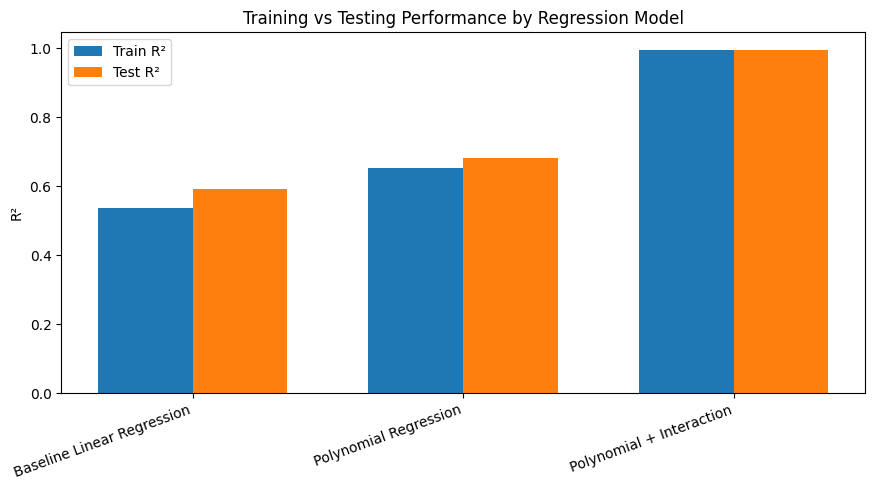

In [ ]:
plt.figure(figsize=(9, 5))

x = np.arange(len(results))
width = 0.35

plt.bar(
    x - width/2,
    results['Train R²'],
    width,
    label='Train R²'
)

plt.bar(
    x + width/2,
    results['Test R²'],
    width,
    label='Test R²'
)

plt.xticks(
    x,
    results['Model'],
    rotation=20,
    ha='right'
)

plt.ylabel('R²')
plt.title('Training vs Testing Performance by Regression Model')
plt.legend()
plt.tight_layout()
plt.show()

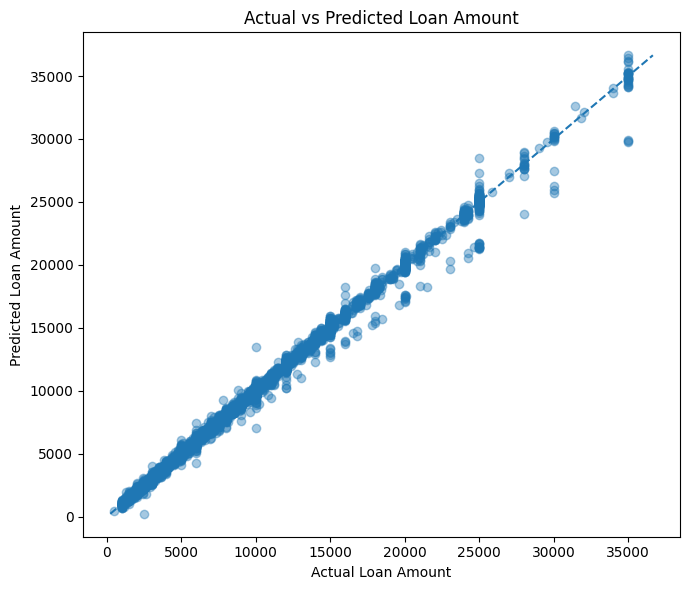

In [ ]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test_int,
    interaction_test_pred,
    alpha=0.4
)

minimum = min(y_test_int.min(), interaction_test_pred.min())
maximum = max(y_test_int.max(), interaction_test_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle='--'
)

plt.xlabel('Actual Loan Amount')
plt.ylabel('Predicted Loan Amount')
plt.title('Actual vs Predicted Loan Amount')
plt.tight_layout()
plt.show()

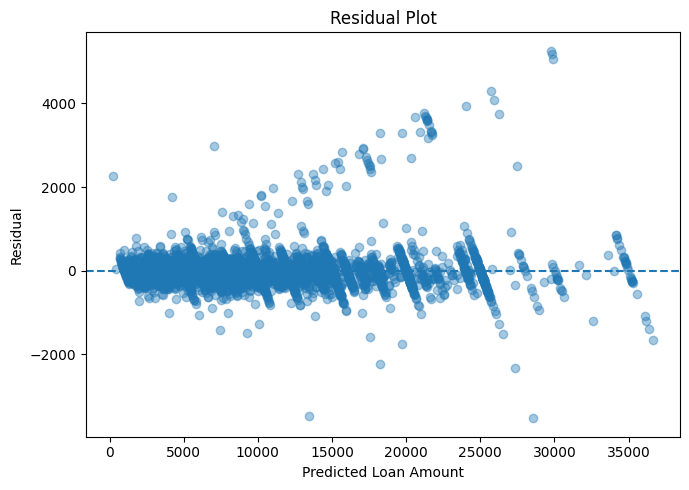

In [ ]:
residuals = y_test_int - interaction_test_pred

plt.figure(figsize=(7, 5))

plt.scatter(
    interaction_test_pred,
    residuals,
    alpha=0.4
)

plt.axhline(0, linestyle='--')

plt.xlabel('Predicted Loan Amount')
plt.ylabel('Residual')
plt.title('Residual Plot')
plt.tight_layout()
plt.show()

## Model Diagnostics and Overfitting

I used a training/test split to evaluate how well each model generalizes to observations that were not used to fit the model.

The training and testing R² values are compared to identify possible overfitting. If polynomial or interaction terms substantially improve training performance without improving testing performance, this would suggest that the additional complexity is fitting patterns specific to the training data rather than improving generalization.

The residual plot is also used to evaluate model behavior. Ideally, residuals should be distributed around zero without a strong systematic pattern. Visible patterns may suggest that the linear regression assumptions do not completely capture the structure of the data.

In [ ]:
best_index = results['Test R²'].idxmax()
best_model = results.loc[best_index, 'Model']

print("MODEL COMPARISON")
print("=" * 60)

display(results.round(4))

print("\nBest model based on Test R²:")
print(best_model)

print("\nChange from baseline to polynomial model:")
print(
    f"Test R² change: "
    f"{poly_test_r2 - baseline_test_r2:+.4f}"
)

print(
    f"RMSE change: "
    f"{poly_rmse - baseline_rmse:+.2f}"
)

print("\nChange from polynomial to interaction model:")
print(
    f"Test R² change: "
    f"{interaction_test_r2 - poly_test_r2:+.4f}"
)

print(
    f"RMSE change: "
    f"{interaction_rmse - poly_rmse:+.2f}"
)

MODEL COMPARISON


,Model,Train R²,Test R²,Test RMSE,Test MAE
0,Baseline Linear Regression,0.5376,0.5929,4046.2360,2901.3276
1,Polynomial Regression,0.6545,0.6819,3576.8690,2374.6890
2,Polynomial + Interaction,0.9965,0.9959,405.7896,212.4333



Best model based on Test R²:
Polynomial + Interaction

Change from baseline to polynomial model:
Test R² change: +0.0890
RMSE change: -469.37

Change from polynomial to interaction model:
Test R² change: +0.3140
RMSE change: -3171.08


## Week 1 Conclusions

This analysis expanded my previous examination of borrower income and loan amount by incorporating multiple borrower and loan characteristics into a regression framework. The results showed that adding polynomial and interaction terms substantially improved the ability of the model to explain variation in loan amount.

### Linear Regression

The baseline multiple linear regression produced a training R² of 0.5376 and a test R² of 0.5929. The test RMSE was 4,046.24 dollars and the MAE was 2,901.33 dollars. This indicates that the baseline model explained approximately 59% of the variation in loan amount in the test data. While this shows that the selected borrower and loan characteristics contain useful information, there was still a considerable amount of variation that the basic linear model did not explain.

### Polynomial Terms

Adding a squared income term improved model performance. Test R² increased from 0.5929 to 0.6819, while RMSE decreased from 4,046.24 to 3,576.87 dollars and MAE decreased from 2,901.33 to 2,374.69 dollars.

This improvement suggests that the relationship between borrower income and loan amount is not entirely linear. Allowing income to have a nonlinear relationship with loan amount captured additional structure that was missed by the baseline model.

### Interaction Terms

The largest improvement occurred after adding the interaction between income and loan percent income. The polynomial and interaction model achieved a training R² of 0.9965 and a test R² of 0.9959. Test RMSE decreased to 405.79 dollars and MAE decreased to 212.43 dollars.

These results suggest that income and loan percent income have an important combined relationship with loan amount. In other words, the relationship between income and loan amount changes depending on how large the loan is relative to the borrower's income. This interaction captured substantially more information than either the baseline or polynomial model alone.

### Multicollinearity

The correlation matrix showed a strong correlation of 0.86 between person age and credit history length. This was also reflected in the VIF analysis, where person age had a VIF of 3.94 and credit history length had a VIF of 3.85. The remaining continuous variables had VIF values close to 1.

Although age and credit history length showed some multicollinearity, none of the VIF values exceeded 5. Therefore, the results do not indicate severe multicollinearity among the continuous predictors.

### Overfitting

I evaluated overfitting by comparing training and testing R². The polynomial and interaction model produced a training R² of 0.9965 and a test R² of 0.9959, a difference of only 0.0006. The similarity between these values provides little evidence of traditional overfitting based on the train/test comparison.

However, the extremely high R² after adding the interaction term was unexpected and should be interpreted carefully. Because loan percent income is mathematically related to both borrower income and loan amount, the interaction between income and loan percent income may indirectly reconstruct information about the target variable. This could explain the unusually strong predictive performance and represents a potential form of target leakage.

### Overall Conclusion

Overall, the Week 1 analysis demonstrates how model specification can substantially affect regression performance. The polynomial term improved performance over the baseline model, providing evidence that the relationship between income and loan amount contains nonlinear behavior. The interaction model produced an even larger improvement, but its near-perfect performance revealed an important modeling concern because loan percent income is derived from variables closely related to the target.

This was an unexpected but useful finding. It shows that strong model performance does not necessarily mean that a model is appropriate. Feature construction and the relationship between predictors and the target must also be considered when evaluating a model. These findings will help guide feature selection and model evaluation in later stages of the project.